# PLIFEPRED: half-life source overview

[Mathur et al., 2018](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0196829) derived the benchmark from **original PEPlife**, not current PEPlife2. Author filters include mammalian blood, length 5–50, half-life 20 s–24 h, modification/structure availability and redundancy removal. The natural 163-view is contained within the mixed 261-view. Context recovered from PEPlife2 is explicitly marked and never overrides author labels.

In [1]:
DATA_SOURCE = "plifepred"
NOTEBOOK_ID = "0_01a_peplife_publication_subsets"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol, CLEAN_COLUMNS
from proteolysis_data_manager.analysis.half_life.overview import cavaco_comparison, dilution_pairs, overlaps, linked_labels, FEATURES
from proteolysis_data_manager.protocols.half_life.conditions import counts, PARAMETERS, plot_conditions
from proteolysis_data_manager.integration.half_life.normalization import known, load_source_records
from proteolysis_data_manager.protocols.half_life.conditions import condition_frame
from proteolysis_data_manager.integration.half_life.labels import CLASS_BINS, CLASS_SCHEME
from proteolysis_data_manager.analysis.half_life.visualization import formatted_table, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS, duration_summary, plot_duration_distributions
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
all_sources = condition_frame(load_source_records(DATA_ROOT))
data = all_sources.loc[all_sources.source.eq(DATA_SOURCE)].copy()
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / NOTEBOOK_ID
RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.12})
def table(frame, name):
    if len(frame)>20: display(HTML(f"<p>Preview: 20 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame)))

def figure(fig, name):
    fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def before_after(before, after, name):
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    for ax,field,label in [(axes[0],"length","Peptide length (residues)"),(axes[1],"half_life_seconds","log10 half-life (minutes; exact point labels)")]:
        a=pd.to_numeric(before[field],errors="coerce").dropna(); b=pd.to_numeric(after[field],errors="coerce").dropna()
        if field=="half_life_seconds":
            a=a[a>0]; b=b[b>0]; bins=time_bins(a,bins=18)
            label="Half-life (physical time; logarithmic spacing)"
        else: bins=np.histogram_bin_edges(a,bins=18) if len(a) else np.linspace(0,1,19)
        ax.hist(a,bins=bins,histtype="step",lw=2,color="#4477AA",label=f"Before (n={len(a)})")
        ax.hist(b,bins=bins,histtype="step",lw=2,color="#EE7733",label=f"After (n={len(b)})")
        if field=="half_life_seconds": readable_time_axis(ax)
        ax.set(xlabel=label,ylabel="Observations"); ax.legend()
    fig.tight_layout(); figure(fig,name)


Source overviews reconstruct the detailed inventory from verified `raw/` files in memory, to inspect original wording and documentation. The public `normalized/observations.parquet` has the compact 23-column contract. See `normalized/remarks_<source>.md` for exceptional label decisions and shared-record enrichment.

## Source size and identities

Count source records, normalized measurements, sequences and documented molecules separately. Shared sequences do not establish independent experiments.

In [2]:
table(pd.DataFrame([counts(data) | {"source_records":data.source_record_id.nunique()}]),"counts.tsv")
table(data.groupby("dataset_view").agg(observations=("observation_id","size"),source_records=("source_record_id","nunique"),sequences=("sequence","nunique")).reset_index(),"dataset_views.tsv")

records,sequences,documented_molecules,publications,source_records
424,234,223,115,261


dataset_view,observations,source_records,sequences
mixed,261,261,234
natural,163,163,163


## Measurement fields and documentation

Missingness and readout semantics are reviewed together. Every source uses the same field definitions:

| Field | Meaning / unit |
|---|---|
| `half_life_seconds` | Exact reported point estimate; null for bounds, intervals, approximations and non-half-life readouts |
| `half_life_mean_seconds` | Populated only when the source documents a mean of half-life estimates |
| `reported_error_seconds` | Explicit ± error, converted to seconds; its statistical type may be unresolved |
| `half_life_sd_seconds`, `half_life_se_seconds` | Only documented SD or SE; unknown error is never relabelled |
| `ci_lower_seconds`, `ci_upper_seconds`, `ci_confidence_level` | Reported CI endpoints and confidence level; missing means null |
| `lower_bound_seconds`, `upper_bound_seconds`, `relation` | Censoring / interval information; these are not confidence intervals |
| `duration_class`, `duration_class_candidates` | Determined class or all compatible classes; no point estimate is invented |
| `ph`, `temperature_c` | Source-reported assay pH and incubation °C, not peptide pI or instrument temperature |
| `matrix_fraction` | Serum/plasma volume fraction, 0–1; dilution is a modeling parameter |
| `peptide_concentration_um` | Explicit molar concentration in µM; mass concentrations and doses remain in raw |

The project class scheme uses short <30 min, medium 30 min–6 h inclusive, and long >6 h. These are the approved project thresholds; they are not the authors’ original labels. It is a project scheme, not the authors' original seven labels. Bounds crossing classes retain a candidate set instead of an arbitrary class. PepMSND's separate binary stable/unstable threshold is not substituted for this scheme.

Source files and text remain unchanged under `raw/`. One source record may produce several clearly separated measurements. Overview notebooks never impute conditions, run acceptance protocols or estimate missing CI.

PEPlife2 2686 (`>1 h`, in vivo) has a reviewed **project-heuristic** medium class; the paper confirms the lower bound, not a 6 h upper bound. Other ambiguous bounds remain unresolved unless reviewed evidence supports one class. See `normalized/remarks_<source>.md` for concrete decisions.

field,documented,missing,total
publication_id,363,61,424
assay,350,74,424
chirality,424,0,424
topology,424,0,424
ph,1,423,424
temperature_c,15,409,424
matrix_fraction,14,410,424
peptide_concentration_um,22,402,424
reported_error_seconds,0,424,424
half_life_sd_seconds,0,424,424


measurement_kind,relation,parse_status,uncertainty_kind,observations
half_life,eq,parsed,not_reported,424


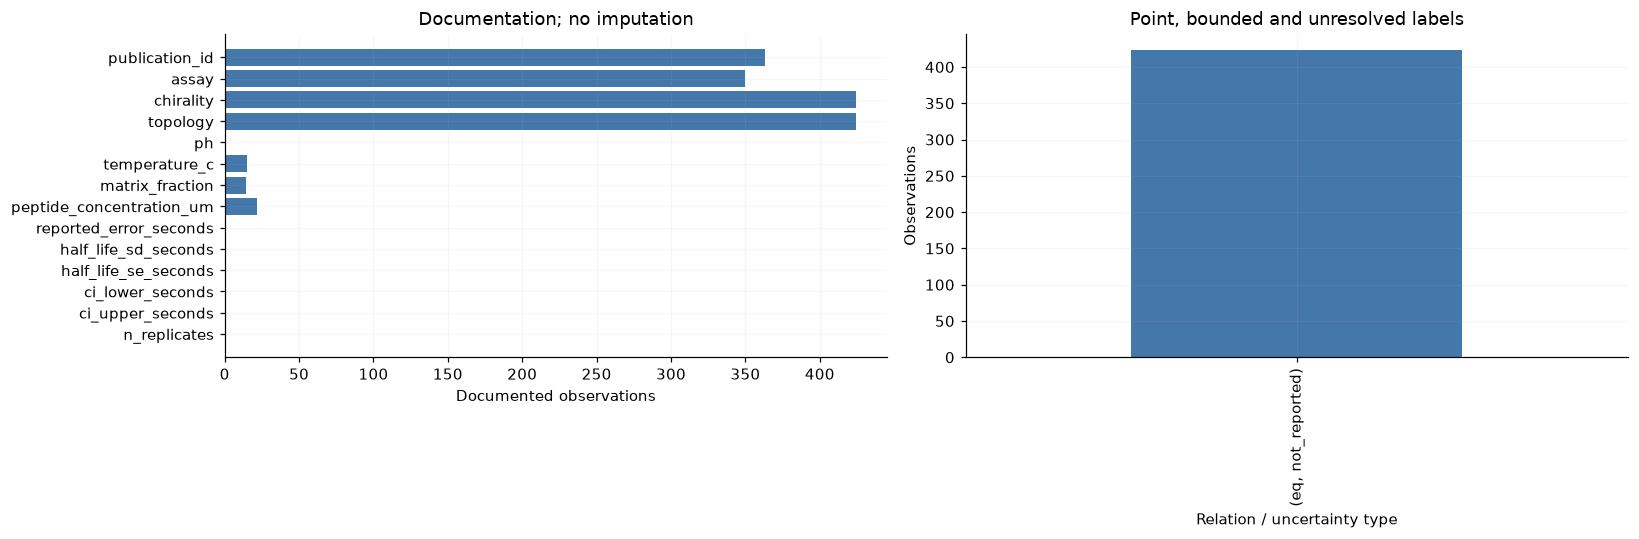

observation_id,half_life_raw,half_life_seconds,reported_error_seconds,uncertainty_kind,ci_lower_seconds,ci_upper_seconds


In [3]:
fields=["publication_id","assay","chirality","topology","ph","temperature_c","matrix_fraction","peptide_concentration_um","reported_error_seconds","half_life_sd_seconds","half_life_se_seconds","ci_lower_seconds","ci_upper_seconds","n_replicates"]
doc=pd.DataFrame([{"field":f,"documented":int(data[f].map(known).sum()),"missing":int((~data[f].map(known)).sum()),"total":len(data)} for f in fields])
table(doc,"documentation.tsv")
table(data.groupby(["measurement_kind","relation","parse_status","uncertainty_kind"],dropna=False).size().rename("observations").reset_index(),"measurement_types.tsv")
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].barh(doc.field.iloc[::-1],doc.documented.iloc[::-1],color="#4477AA"); axes[0].set(xlabel="Documented observations",title="Documentation; no imputation")
data.groupby(["relation","uncertainty_kind"]).size().plot.bar(ax=axes[1],color="#4477AA"); axes[1].set(ylabel="Observations",xlabel="Relation / uncertainty type",title="Point, bounded and unresolved labels")
fig.tight_layout(); figure(fig,"documentation_and_labels.png")
table(data[data.reported_error_seconds.notna()][["observation_id","half_life_raw","half_life_seconds","reported_error_seconds","uncertainty_kind","ci_lower_seconds","ci_upper_seconds"]],"reported_plus_minus.tsv")

## General distributions

| Duration class | Time interval | Assignment |
|---|---|---|
| unresolved | No unique interval | Missing/unparsed/approximate label or censoring spanning multiple classes |
| short | Less than 60 minutes | Exact point or a bound that uniquely implies this class |
| medium | From 60 minutes up to 6 hours (upper limit excluded) | Exact point or a uniquely implied class |
| long | At least 6 hours | Exact point or a uniquely implied class |

Classes always appear in this order and use the same colors across plots and tables. The class counts include exact and class-only labels together. The half-life histogram includes only exact numeric labels, so its denominator differs. The time axis uses logarithmic spacing but labels are seconds/minutes/hours/days, not log10 values. These distributions are descriptive, not acceptance criteria.

duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records
unresolved,no unique interval,0,0,0
short,<30 min,268,268,0
medium,30 min–6 h,104,104,0
long,>6 h,52,52,0


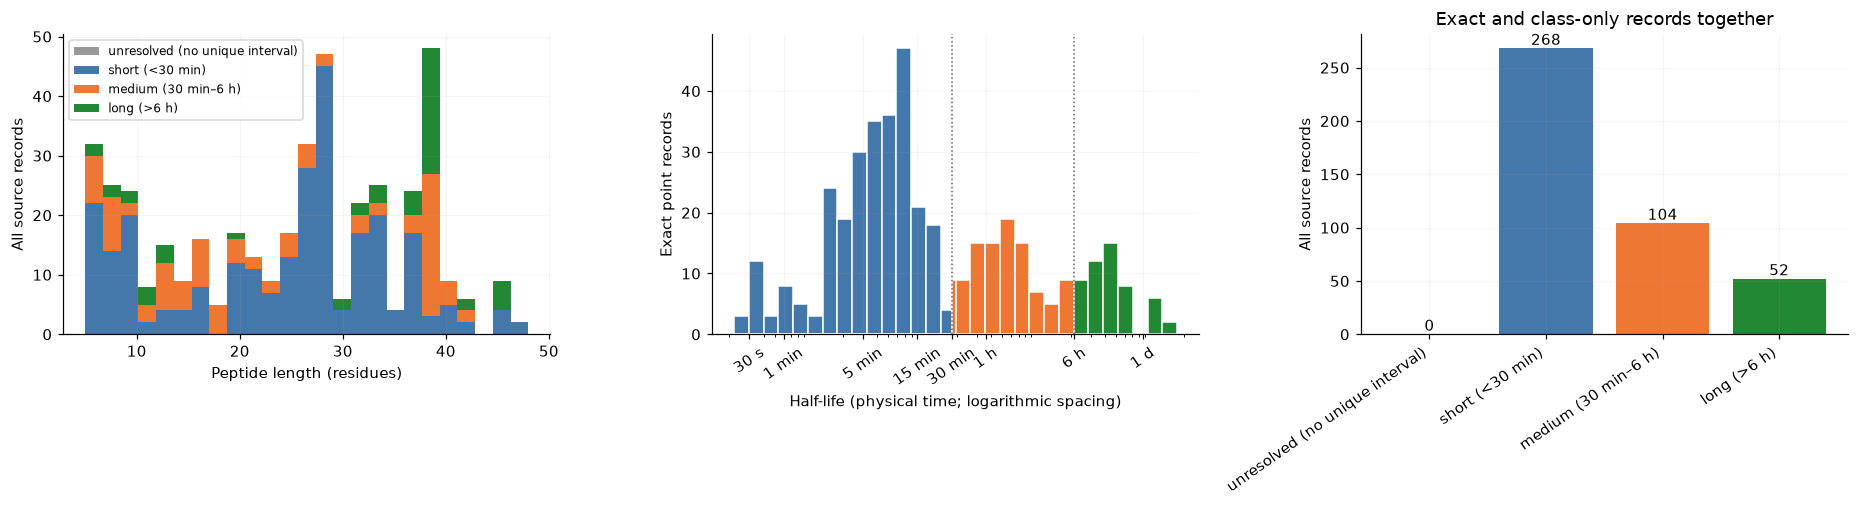

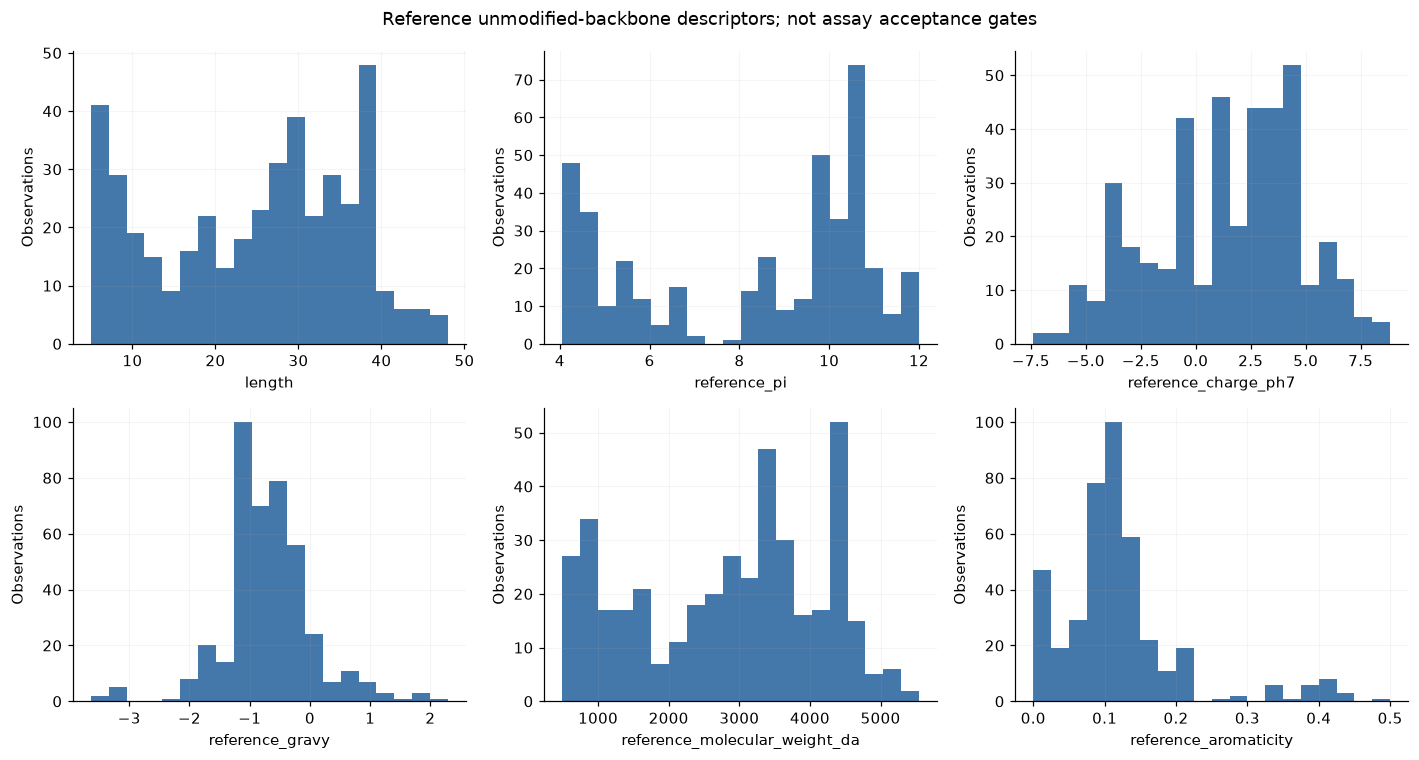

In [4]:
table(duration_summary(data),"duration_classes.tsv")
figure(plot_duration_distributions(data),"general_distributions.png")
fig,axes=plt.subplots(2,3,figsize=(13,7))
for ax,feature in zip(axes.flat,FEATURES[:6]):
 v=data[feature].dropna(); ax.hist(v,bins=20,color="#4477AA"); ax.set(xlabel=feature,ylabel="Observations")
fig.suptitle("Reference unmodified-backbone descriptors; not assay acceptance gates"); fig.tight_layout(); figure(fig,"peptide_descriptors.png")

## Proteolytic environments

Keep human/mouse/other species, serum/plasma and in vivo/in vitro separate. Unknown context remains unknown in overviews.

species,matrix,in_vivo_in_vitro,observations
rat,plasma,in vivo,116
unknown,other,unknown,61
monkey,plasma,in vivo,37
rat,other,in vivo,29
human,plasma,in vivo,25
human,plasma,in vitro,23
human,serum,in vitro,17
mouse,serum,in vivo,15
dog,plasma,in vivo,11
unknown,other,in vivo,10


species,matrix,in_vivo_in_vitro,test_sample_raw,observations
bovine,serum,in vitro,Fetal bovine serum batch4,2
bovine,serum,in vivo,Bovine serum,1
dog,other,in vivo,Injected intravenously into dogs,2
dog,plasma,in vivo,Dogs plasma,1
dog,plasma,in vivo,Intravenous infusion in Dog plasma,2
dog,plasma,in vivo,Mongrel dog plasma(Dose i/v injected),7
dog,plasma,in vivo,Six mongrel dogs plasma (Dose i/v injected),1
human,other,in vivo,Human plamsa,2
human,other,in vivo,Intravenous administration to human,2
human,plasma,in vitro,Human blood plasma,2


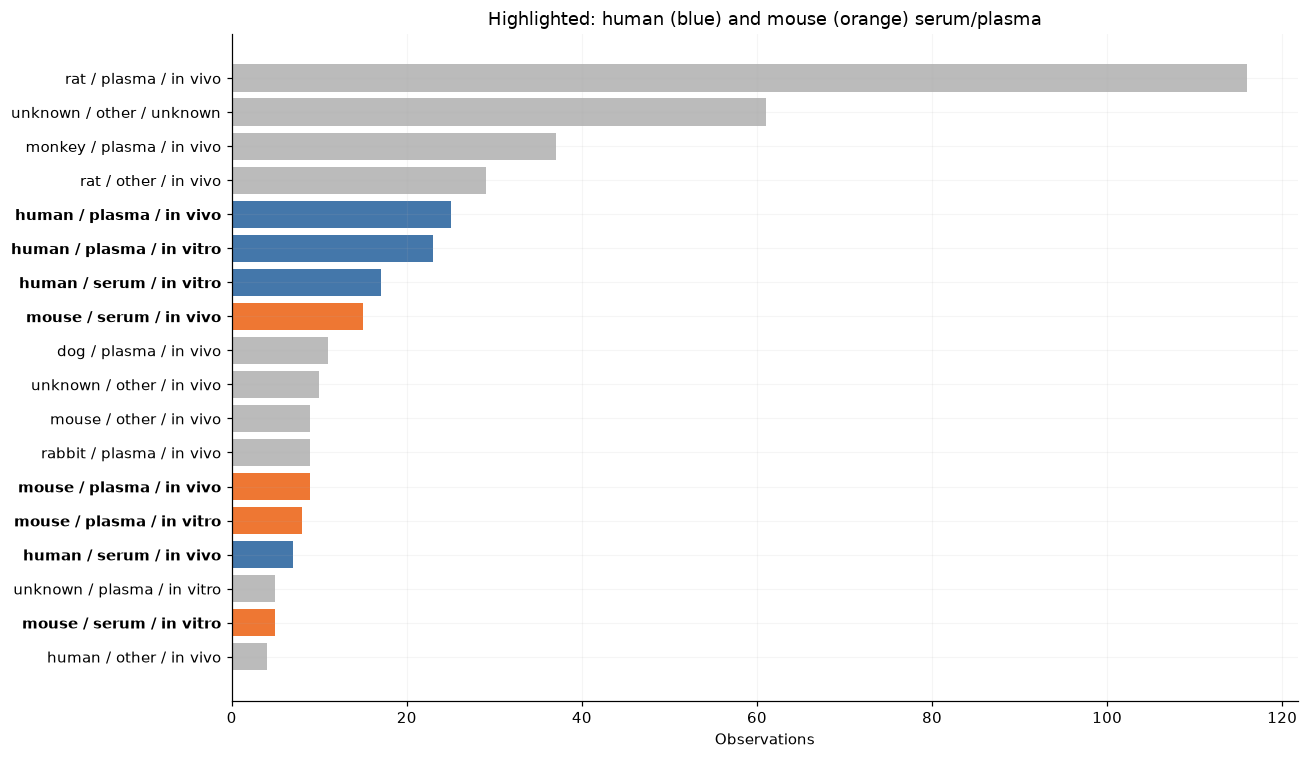

In [5]:
environments=data.groupby(["species","matrix","in_vivo_in_vitro"],dropna=False).size().rename("observations").reset_index().sort_values("observations",ascending=False)
table(environments,"environments.tsv")
table(data.groupby(["species","matrix","in_vivo_in_vitro","test_sample_raw"],dropna=False).size().rename("observations").reset_index(),"raw_environments.tsv")
focus=environments.species.isin(["human","mouse"]) & environments.matrix.isin(["serum","plasma"])
top=pd.concat([environments[focus],environments[~focus].head(max(0,18-int(focus.sum())))]).sort_values("observations")
fig,ax=plt.subplots(figsize=(12,7))
colors=["#4477AA" if r.species=="human" and r.matrix in ["serum","plasma"] else ("#EE7733" if r.species=="mouse" and r.matrix in ["serum","plasma"] else "#BBBBBB") for r in top.itertuples()]
ax.barh(top[["species","matrix","in_vivo_in_vitro"]].agg(" / ".join,axis=1),top.observations,color=colors)
for tick,r in zip(ax.get_yticklabels(),top.itertuples()):
 if r.species in ["human","mouse"] and r.matrix in ["serum","plasma"]: tick.set_fontweight("bold")
ax.set(xlabel="Observations",title="Highlighted: human (blue) and mouse (orange) serum/plasma")
fig.tight_layout(); figure(fig,"environments.png")

## Cavaco reference: shared observations and population context

Cavaco is shown in every source overview. A shared sequence is an audit candidate, not proof of matching chemistry or an independent measurement. If overlap is absent, distribution comparisons alone cannot establish source accuracy. No CI is transferred from a sequence match.

source,shared_sequences,matched_source_rows,full_chemistry_matches,same_environment
plifepred,0,0,0,0


source,source_observation_id,cavaco_observation_id,sequence,source_seconds,cavaco_seconds,ci95_lower_seconds,ci95_upper_seconds,difference_seconds,relative_difference,inside_cavaco_ci95,chemistry_match,same_environment,source_c_terminal,cavaco_c_terminal,interpretation


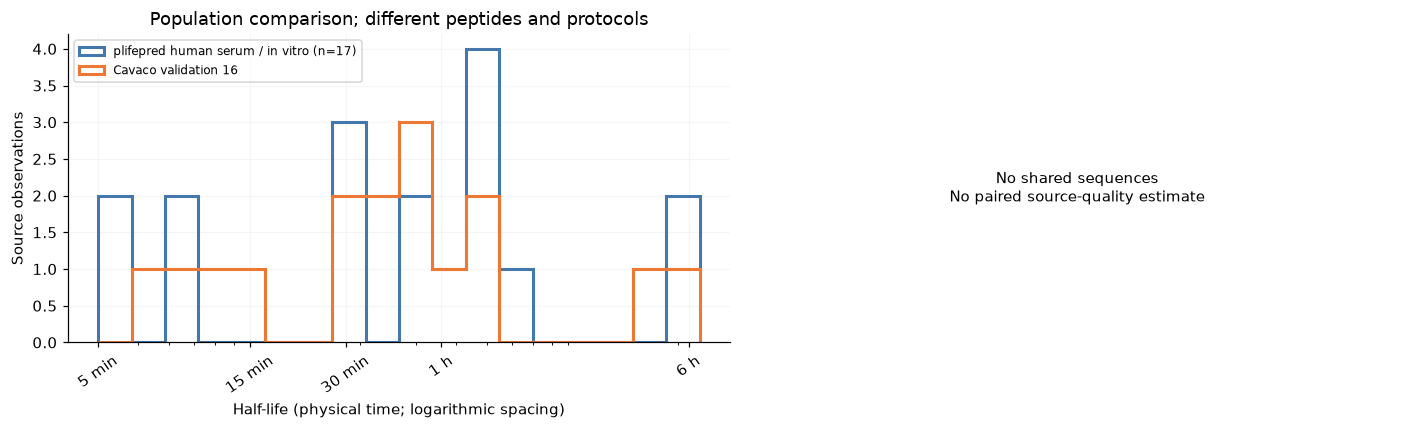

In [6]:
cavaco=all_sources[all_sources.source.eq("cavaco")]
comparison=cavaco_comparison(all_sources,DATA_SOURCE)
table(pd.DataFrame([{"source":DATA_SOURCE,"shared_sequences":comparison.sequence.nunique(),"matched_source_rows":len(comparison),"full_chemistry_matches":int(comparison.chemistry_match.sum()),"same_environment":int(comparison.same_environment.sum())}]),"cavaco_overlap_summary.tsv")
table(comparison,"cavaco_shared_sequence_audit.tsv")
fig,axes=plt.subplots(1,2,figsize=(13,4))
selected=data[data.species.eq("human") & data.matrix.eq("serum") & data.in_vivo_in_vitro.eq("in vitro") & data.regression_label_available]
a=selected.half_life_seconds; b=cavaco.half_life_seconds
bins=time_bins(np.concatenate([a,b]),bins=18)
axes[0].hist(a,bins=bins,histtype="step",lw=2,label=f"{DATA_SOURCE} human serum / in vitro (n={len(a)})",color="#4477AA")
axes[0].hist(b,bins=bins,histtype="step",lw=2,label="Cavaco validation 16",color="#EE7733")
readable_time_axis(axes[0])
axes[0].set(xlabel="Half-life (physical time; logarithmic spacing)",ylabel="Source observations",title="Population comparison; different peptides and protocols"); axes[0].legend(fontsize=8)
valid=comparison[comparison.source_seconds.notna()]
if len(valid):
 axes[1].errorbar(valid.cavaco_seconds/60,valid.source_seconds/60,xerr=np.vstack([(valid.cavaco_seconds-valid.ci95_lower_seconds)/60,(valid.ci95_upper_seconds-valid.cavaco_seconds)/60]),fmt="o",capsize=3,color="#4477AA")
 lo=min(valid.cavaco_seconds.min(),valid.source_seconds.min())/60; hi=max(valid.cavaco_seconds.max(),valid.source_seconds.max())/60
 axes[1].plot([lo,hi],[lo,hi],ls="--",color="#999999"); axes[1].set(xscale="log",yscale="log",xlabel="Cavaco half-life (minutes; 95% CI)",ylabel="Source half-life (minutes)",title="Shared-sequence labels; chemistry checked separately")
else:
 axes[1].text(.5,.5,"No shared sequences\nNo paired source-quality estimate",transform=axes[1].transAxes,ha="center",va="center"); axes[1].set_axis_off()
fig.tight_layout(); figure(fig,"cavaco_reference_comparison.png")

## Benchmark selection, recovered metadata and changed labels

Compare the published views against current PEPlife2. Author exclusion reasons describe construction, not proof that rejected records are bad measurements. The natural and mixed views must not be summed as independent datasets.

In [7]:
related=all_sources[all_sources.source.isin(["peplife2","plifepred"])]
table(overlaps(related),"peplife_benchmark_overlap.tsv")
table(linked_labels(related),"peplife_benchmark_label_changes.tsv")
table(data.groupby(["dataset_view","metadata_origin","linked_label_status"]).size().rename("observations").reset_index(),"benchmark_provenance.tsv")

dataset_a,dataset_b,scope,n_sequences_a,n_sequences_b,sequence_intersection,sequence_jaccard,chemistry_intersection_where_complete,n_chemistry_known_a,n_chemistry_known_b
peplife2/all,plifepred/mixed,all_source_rows,1808,234,230,0.1269,217,1635,223
peplife2/all,plifepred/natural,all_source_rows,1808,163,163,0.09015,163,1635,163
plifepred/mixed,plifepred/natural,all_source_rows,234,163,163,0.6966,163,223,163


observation_id,peplife2_id,is_human_serum,author_relation,author_seconds,peplife2_relation,peplife2_seconds,peplife2_lower,peplife2_upper,same_label,compatible_with_reported_label,note
plifepred:natural:1003,1003,True,eq,1800,lt,None,None,1800,False,False,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1111,1111,False,eq,4.32e+04,gt,None,4.32e+04,None,False,False,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1218,1218,False,eq,1110,unknown,None,None,None,False,None,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1681,1681,False,eq,40,unknown,None,None,None,False,None,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1687,1687,False,eq,2550,unknown,None,None,None,False,None,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1688,1688,False,eq,1.8e+04,approx,None,None,None,False,None,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1715,1715,False,eq,60,lt,None,None,60,False,False,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1990,1990,False,eq,2.4e+04,gt,None,2.4e+04,None,False,False,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:1993,1993,False,eq,3.6e+04,unknown,None,None,None,False,None,"Matched source ID, name and recorded chemistry; author label retained."
plifepred:natural:2051,2051,False,eq,4.32e+04,approx,None,None,None,False,None,"Matched source ID, name and recorded chemistry; author label retained."


dataset_view,metadata_origin,linked_label_status,observations
mixed,direct,not_linked,38
mixed,peplife2_id_and_chemistry_match,precision_or_censoring_changed,45
mixed,peplife2_id_and_chemistry_match,same_label,178
natural,direct,not_linked,23
natural,peplife2_id_and_chemistry_match,precision_or_censoring_changed,25
natural,peplife2_id_and_chemistry_match,same_label,115
